--- Verifiche Attività 1 ---
mu(x) è finita? True
mu(x) è non negativa? True
mu(x) è simmetrica? True
mu(0) compatibile con B+I0? True


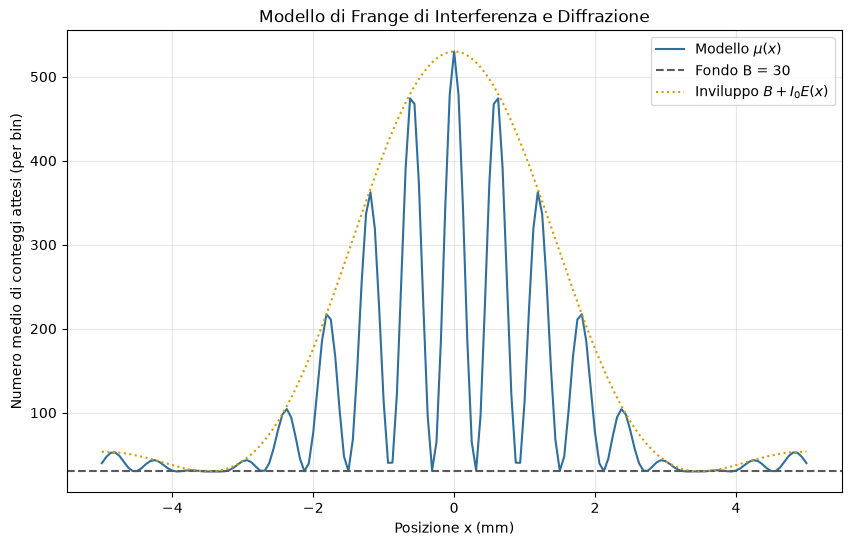

N_c simulato:9739
mu_c:9756.766302371667
Nc-mu_c : -17.766302371666825
sqrt(mu_c) : 98.77634485225532
deltaN/sqrt(N)-0.1798639380535974


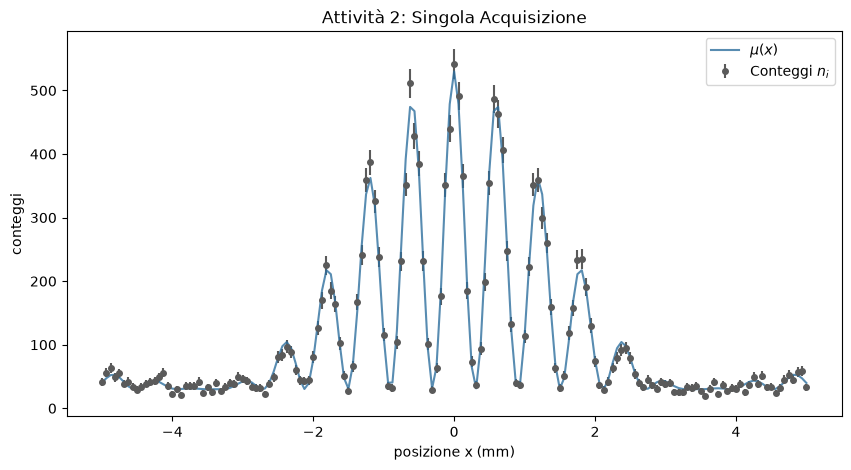

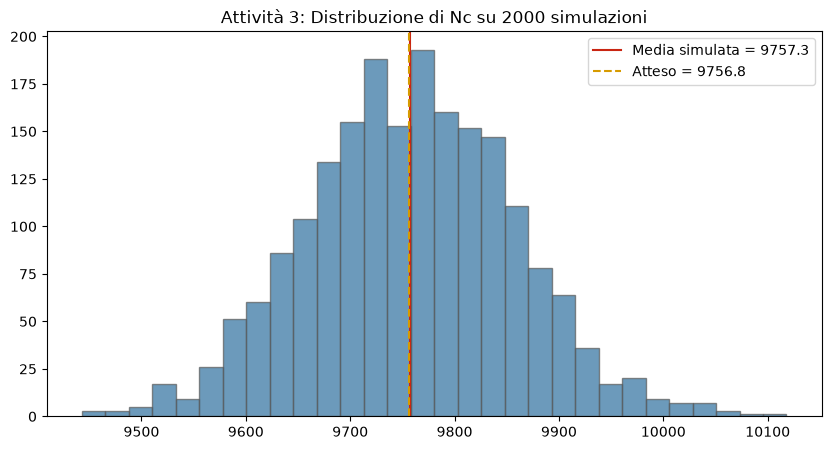

In [1]:
# %%
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit

ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ORO = "#D79B00"
B = 30
I = 500
a = 0.9
d = 5.2
x = np.linspace(-5.0,5.0,161)
def calcola_modello(B,I,a,d,x):
    Ex = (np.sinc(a*x/np.pi))**2
    Cx = np.cos(d*x)**2
    Mux = B + I*(Ex*Cx)
    inviluppo_superiore = B + I*Ex
    return Ex,Cx,Mux,inviluppo_superiore
def simulazione_acquisizione(Mux):
    n_i = stats.poisson.rvs(Mux)
    return n_i
def simulazione_multipla(Mux,maschera,M=2000):
    matrice_simulazioni = stats.poisson.rvs(Mux, size=(M, len(Mux)))
    Nc_distribuzione = np.sum(matrice_simulazioni[:, maschera], axis=1)
    return Nc_distribuzione
Ex,Cx,Mux,inviluppo_superiore = calcola_modello(B,I,a,d,x)
n_i = simulazione_acquisizione(Mux) 
errori = np.maximum(np.sqrt(n_i), 1) 
#----attività 1----(grafico modello)
print("--- Verifiche Attività 1 ---")
print(f"mu(x) è finita? {np.all(np.isfinite(Mux))}") 
print(f"mu(x) è non negativa? {np.all(Mux >= 0)}") 
print(f"mu(x) è simmetrica? {np.allclose(Mux, Mux[::-1])}") 
indice_zero = np.where(x == 0)[0][0] 
print(f"mu(0) compatibile con B+I0? {np.isclose(Mux[indice_zero], B + I)}") 
plt.figure(figsize=(10, 6)) 
plt.plot(x, Mux, label=r'Modello $\mu(x)$', color=AZZURRO) 
plt.axhline(y=B, color=GRIGIO, linestyle='--', label=f'Fondo B = {B}') 
plt.plot(x, inviluppo_superiore, color=ORO, linestyle=':', label=r'Inviluppo $B + I_0 E(x)$')
 
plt.title('Modello di Frange di Interferenza e Diffrazione') 
plt.xlabel('Posizione x (mm)') 
plt.ylabel('Numero medio di conteggi attesi (per bin)') 
plt.legend() 
plt.grid(True, alpha=0.3) 
plt.show()
#----attività 2---------(grafico aquisizione singola)
regione_centrale = np.abs(x) < 1.2 
N_c = np.sum(n_i[regione_centrale])
mu_c = np.sum(Mux[regione_centrale])
errore_statistico = np.sqrt(mu_c)
print(f"N_c simulato:{N_c}")
print(f"mu_c:{mu_c}")
print(f"Nc-mu_c : {N_c - mu_c}")
print(f"sqrt(mu_c) : {errore_statistico}")
print(f"deltaN/sqrt(N){(N_c - mu_c)/errore_statistico}")

plt.figure(figsize=(10,5))
plt.errorbar(x,n_i,yerr=errori, fmt='o',color=GRIGIO, markersize=4, label='Conteggi $n_i$')
plt.plot(x, Mux, color=AZZURRO, alpha=0.8, label=r'$\mu(x)$')
plt.legend()
plt.title("Attività 2: Singola Acquisizione")
plt.xlabel("posizione x (mm)")
plt.ylabel("conteggi")
plt.show()
maschera_centrale = np.abs(x) < 1.2 
M = 2000 
Nc_distribuzione = simulazione_multipla(Mux, maschera_centrale, M)
 # Calcolo statistiche finali (Attività 3) 
media_Nc = np.mean(Nc_distribuzione) 
mu_c = np.sum(Mux[maschera_centrale])
 # Grafico Distribuzione (Attività 3)
plt.figure(figsize=(10, 5)) 
plt.hist(Nc_distribuzione, bins=30, color=AZZURRO, edgecolor=GRIGIO, alpha=0.7) 
plt.axvline(media_Nc, color=ROSSO, label=f'Media simulata = {media_Nc:.1f}') 
plt.axvline(mu_c, color=ORO, linestyle='--', label=f'Atteso = {mu_c:.1f}') 
plt.legend() 
plt.title(f"Attività 3: Distribuzione di Nc su {M} simulazioni") 
plt.show()



In [ ]:
B = 30
I = 500
a = 0.9
d = 5.2
x = np.linspace(-5.0,5.0,161)
def data_set(B,I,a,d,x): 
    Ex = (np.sinc(a*x/np.pi))**2
    Cx = np.cos(d*x)**2
    Mux = B + I*(Ex*Cx)
    return Mux